# Ejercicio 6 — Mediciones con ruido y mínimos cuadrados

**Etiqueta de uso de IA:** *Asistencia para destrabar / corregir*.

Hasta acá las mediciones eran exactas. En una adquisición real el detector cuenta fotones y
esa cuenta es aleatoria; además hay ruido electrónico, redondeos y errores del propio modelo
(el objeto no es realmente constante por píxel). Modelamos todo eso con una perturbación
aditiva

$$b_\sigma = b_7 + \eta_\sigma, \qquad b_7 = A_7\,x_{\text{fantoma}} .$$

Con ruido, en general **no existe** ninguna imagen que reproduzca exactamente todas las
mediciones: $b_\sigma \notin \operatorname{Col}(A_7)$, porque $\operatorname{Col}(A_7)$ es
un subespacio de dimensión $64$ dentro de $\mathbb{R}^{119}$ y el ruido tiene componente
fuera de él. El sistema $A_7 x = b_\sigma$ pasa a ser **incompatible**, y lo reemplazamos
por el problema de **mínimos cuadrados**

$$\hat{x}_\sigma = \arg\min_{x}\ \|A_7 x - b_\sigma\|^2 ,$$

que busca la imagen cuyas mediciones simuladas queden lo más cerca posible de las medidas.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs("figuras", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "image.cmap": "gray"})


def guardar(fig, nombre):
    # Guarda la figura en figuras/, como pide el formato de entrega.
    fig.savefig(os.path.join("figuras", nombre + ".png"), bbox_inches="tight", dpi=150)


X_fantoma = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
    [0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
    [0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

n = 8
x_fantoma = X_fantoma.reshape(-1)   # k = i*n + j


def mascara_rayo(n, direccion, s):
    # M[i,j] = 1  <=>  alpha*i + beta*j == s
    alpha, beta = direccion
    i = np.arange(n).reshape(n, 1)
    j = np.arange(n).reshape(1, n)
    return (alpha * i + beta * j == s).astype(float)


def matriz_proyeccion(n, direcciones):
    # Devuelve A (m x n^2) y la lista de pares ((alpha, beta), s) de cada fila.
    i = np.arange(n).reshape(n, 1)
    j = np.arange(n).reshape(1, n)
    filas, info = [], []
    for direccion in direcciones:
        alpha, beta = direccion
        valores_s = np.unique(alpha * i + beta * j)   # np.unique ya devuelve ordenado
        for s in valores_s:
            filas.append(mascara_rayo(n, direccion, int(s)).reshape(-1))
            info.append((direccion, int(s)))
    return np.array(filas, dtype=float), info


D2 = [(1, 0), (0, 1)]
D4 = D2 + [(1, 1), (1, -1)]
D7 = D4 + [(2, 1), (1, 2), (3, 1)]


A7, info7 = matriz_proyeccion(n, D7)
b7 = A7 @ x_fantoma

print("A7:", A7.shape, "  rango:", np.linalg.matrix_rank(A7))
print("b7:", b7.shape)
print("número de condición cond(A7) =", round(float(np.linalg.cond(A7)), 4))

A7: (119, 64)   rango: 64
b7: (119,)
número de condición cond(A7) = 8.4286


## a) Generación del ruido

Fijamos una semilla para que todo el ejercicio sea reproducible y generamos **un único**
vector $z$ con componentes gaussianas estándar, del mismo tamaño que $b_7$. Definimos

$$\text{escala} = \sqrt{\tfrac{1}{m}\textstyle\sum_r (b_7)_r^2} = \text{RMS}(b_7),$$

que representa el tamaño típico de una medición, y para cada nivel
$\sigma \in \{0,\,0.01,\,0.03,\,0.06,\,0.10\}$ tomamos

$$\eta_\sigma = \sigma \cdot \text{escala} \cdot z, \qquad b_\sigma = b_7 + \eta_\sigma .$$

Usar **el mismo** $z$ en todos los casos es importante: así lo único que cambia entre
niveles es la *intensidad* del ruido, no su realización, y las comparaciones son limpias.
Con esta definición, $\sigma = 0.03$ significa un ruido cuyo desvío estándar es
aproximadamente el $3\%$ del tamaño típico de las mediciones.

In [2]:
rng = np.random.default_rng(42)          # semilla fija: resultados reproducibles
z = rng.standard_normal(b7.shape[0])

escala = np.sqrt(np.mean(b7**2))
sigmas = [0.0, 0.01, 0.03, 0.06, 0.10]

print("escala = RMS(b7) =", round(float(escala), 6))
print("||b7||           =", round(float(np.linalg.norm(b7)), 6))
print("z: media =", round(float(z.mean()), 4), "  desvío =", round(float(z.std()), 4))
print()

b_sigma = {}
for s in sigmas:
    eta = s * escala * z
    b_sigma[s] = b7 + eta
    print(f"σ = {s:<5}  ||η|| = {np.linalg.norm(eta):7.4f}   "
          f"||η||/||b7|| = {np.linalg.norm(eta) / np.linalg.norm(b7):7.4f}")

escala = RMS(b7) = 1.096327
||b7||           = 11.959515
z: media = -0.0589   desvío = 0.7847

σ = 0.0    ||η|| =  0.0000   ||η||/||b7|| =  0.0000
σ = 0.01   ||η|| =  0.0941   ||η||/||b7|| =  0.0079
σ = 0.03   ||η|| =  0.2823   ||η||/||b7|| =  0.0236
σ = 0.06   ||η|| =  0.5647   ||η||/||b7|| =  0.0472
σ = 0.1    ||η|| =  0.9411   ||η||/||b7|| =  0.0787


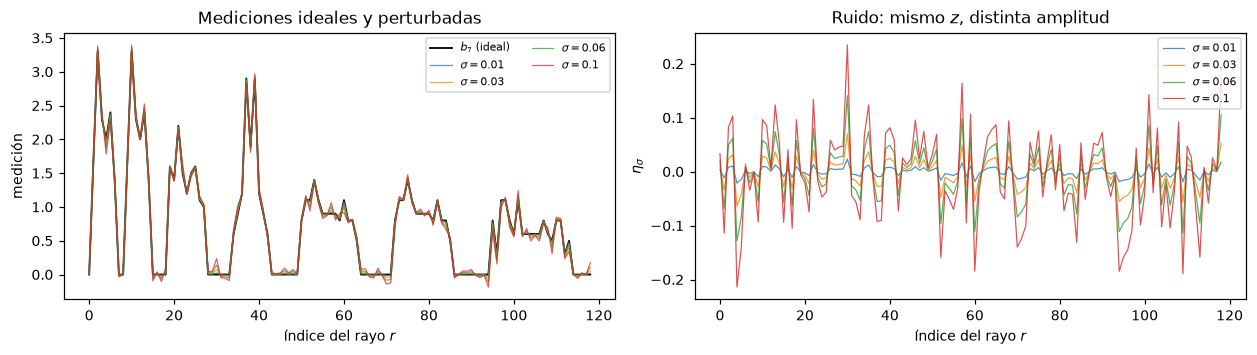

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.3))

axes[0].plot(b7, "k-", lw=1.2, label=r"$b_7$ (ideal)")
for s in sigmas[1:]:
    axes[0].plot(b_sigma[s], lw=0.8, alpha=0.75, label=fr"$\sigma = {s}$")
axes[0].set_xlabel("índice del rayo $r$")
axes[0].set_ylabel("medición")
axes[0].set_title("Mediciones ideales y perturbadas")
axes[0].legend(fontsize=7, ncol=2)

for s in sigmas[1:]:
    axes[1].plot(b_sigma[s] - b7, lw=0.8, alpha=0.8, label=fr"$\sigma = {s}$")
axes[1].set_xlabel("índice del rayo $r$")
axes[1].set_ylabel(r"$\eta_\sigma$")
axes[1].set_title(r"Ruido: mismo $z$, distinta amplitud")
axes[1].legend(fontsize=7)

fig.tight_layout()
guardar(fig, "ejercicio_06a_ruido")
plt.show()

## b) Reconstrucción por mínimos cuadrados para cada nivel de ruido

Como $A_7$ tiene rango columna completo, $A_7^{T}A_7$ es inversible y la solución de
mínimos cuadrados es **única**:

$$\hat{x}_\sigma = (A_7^{T}A_7)^{-1}A_7^{T}b_\sigma .$$

Usamos `np.linalg.lstsq`, que lo resuelve por SVD (numéricamente más estable que formar las
ecuaciones normales).

In [4]:
reconstrucciones = {}
tabla = []

for s in sigmas:
    b = b_sigma[s]
    x_hat, *_ = np.linalg.lstsq(A7, b, rcond=None)
    reconstrucciones[s] = x_hat

    norma_ruido = np.linalg.norm(b - b7)
    norma_residuo = np.linalg.norm(b - A7 @ x_hat)
    err_rel = np.linalg.norm(x_hat - x_fantoma) / np.linalg.norm(x_fantoma)
    tabla.append((s, norma_ruido, norma_residuo, err_rel, x_hat.min(), x_hat.max()))

enc = (f"{'σ':>6} {'||η||':>9} {'||b_σ - A7 x̂||':>16} {'error rel.':>12} "
       f"{'mín':>9} {'máx':>9}")
print(enc)
print("-" * len(enc))
for s, nr, nres, err, mn, mx in tabla:
    print(f"{s:>6} {nr:>9.4f} {nres:>16.4f} {err:>12.4f} {mn:>9.4f} {mx:>9.4f}")
print()
print(f"(el fantoma original tiene mín = {x_fantoma.min():.4f} y "
      f"máx = {x_fantoma.max():.4f})")

     σ     ||η||  ||b_σ - A7 x̂||   error rel.       mín       máx
------------------------------------------------------------------
   0.0    0.0000           0.0000       0.0000   -0.0000    0.8000
  0.01    0.0941           0.0585       0.0163   -0.0123    0.8112
  0.03    0.2823           0.1755       0.0488   -0.0370    0.8337
  0.06    0.5647           0.3511       0.0975   -0.0741    0.8674
   0.1    0.9411           0.5851       0.1626   -0.1235    0.9123

(el fantoma original tiene mín = 0.0000 y máx = 0.8000)


In [5]:
# Relación entre la norma del ruido, la del residuo y la del error.
print(f"{'σ':>6} {'||η||':>9} {'||r||':>9} {'||r||/||η||':>13} "
      f"{'err.rel.x':>11} {'err.rel.b':>11} {'amplific.':>10}")
print("-" * 74)
for s, nr, nres, err, mn, mx in tabla:
    err_b = nr / np.linalg.norm(b7)
    amp = err / err_b if err_b > 0 else np.nan
    cociente = nres / nr if nr > 0 else np.nan
    print(f"{s:>6} {nr:>9.4f} {nres:>9.4f} {cociente:>13.4f} "
          f"{err:>11.4f} {err_b:>11.4f} {amp:>10.2f}")

     σ     ||η||     ||r||   ||r||/||η||   err.rel.x   err.rel.b  amplific.
--------------------------------------------------------------------------
   0.0    0.0000    0.0000           nan      0.0000      0.0000        nan
  0.01    0.0941    0.0585        0.6218      0.0163      0.0079       2.07
  0.03    0.2823    0.1755        0.6218      0.0488      0.0236       2.07
  0.06    0.5647    0.3511        0.6218      0.0975      0.0472       2.07
   0.1    0.9411    0.5851        0.6218      0.1626      0.0787       2.07


Dos regularidades saltan a la vista y son consecuencia directa de la linealidad del
problema:

1. $\|r\| / \|\eta\|$ es **constante** ($\approx 0.62$). El residuo es la proyección del
   ruido sobre $\operatorname{Col}(A_7)^{\perp}$, un subespacio fijo de dimensión
   $119 - 64 = 55$; al escalar $\eta$ por $\sigma$, su proyección escala igual.
2. El factor de amplificación (error relativo de la imagen dividido por el error relativo de
   las mediciones) también es constante, $\approx 2$. Está acotado por el número de
   condición $\kappa(A_7) = \sigma_{\max}/\sigma_{\min} \approx 8.4$, que es moderado: $A_7$
   está bien condicionada y el problema, con estas direcciones, es razonablemente estable.

escala de color común: [-0.123, 0.912]


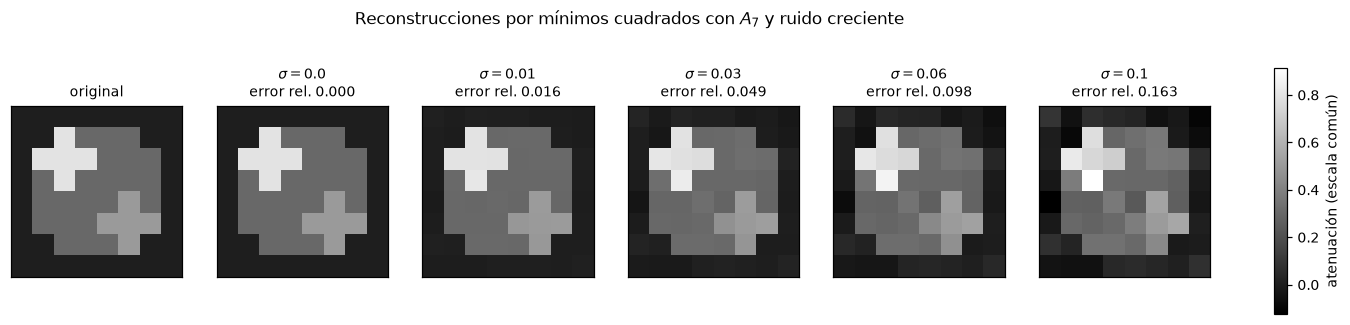

In [6]:
imagenes = [reconstrucciones[s].reshape(n, n) for s in sigmas]
vmin = min(X_fantoma.min(), min(M.min() for M in imagenes))
vmax = max(X_fantoma.max(), max(M.max() for M in imagenes))
print(f"escala de color común: [{vmin:.3f}, {vmax:.3f}]")

fig, axes = plt.subplots(1, 6, figsize=(15.0, 2.9))
im = axes[0].imshow(X_fantoma, cmap="gray", vmin=vmin, vmax=vmax)
axes[0].set_title("original", fontsize=9)
axes[0].set_xticks([]); axes[0].set_yticks([])

for ax, s, M, (_, _, _, err, _, _) in zip(axes[1:], sigmas, imagenes, tabla):
    im = ax.imshow(M, cmap="gray", vmin=vmin, vmax=vmax)
    ax.set_title(f"$\\sigma = {s}$\nerror rel. {err:.3f}", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])

fig.colorbar(im, ax=axes, fraction=0.012, label="atenuación (escala común)")
fig.suptitle(r"Reconstrucciones por mínimos cuadrados con $A_7$ y ruido creciente", y=1.06)
guardar(fig, "ejercicio_06b_reconstrucciones")
plt.show()

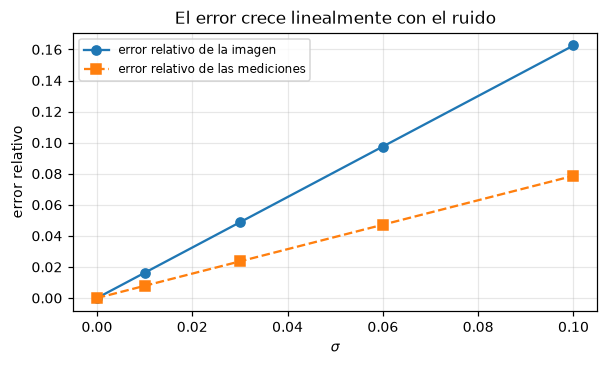

In [7]:
fig, ax = plt.subplots(figsize=(5.6, 3.4))
sig = np.array(sigmas)
ax.plot(sig, [t[3] for t in tabla], "o-", label="error relativo de la imagen")
ax.plot(sig, [t[1] / np.linalg.norm(b7) for t in tabla], "s--",
        label="error relativo de las mediciones")
ax.set_xlabel(r"$\sigma$")
ax.set_ylabel("error relativo")
ax.set_title("El error crece linealmente con el ruido")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
guardar(fig, "ejercicio_06b_error_vs_sigma")
plt.show()

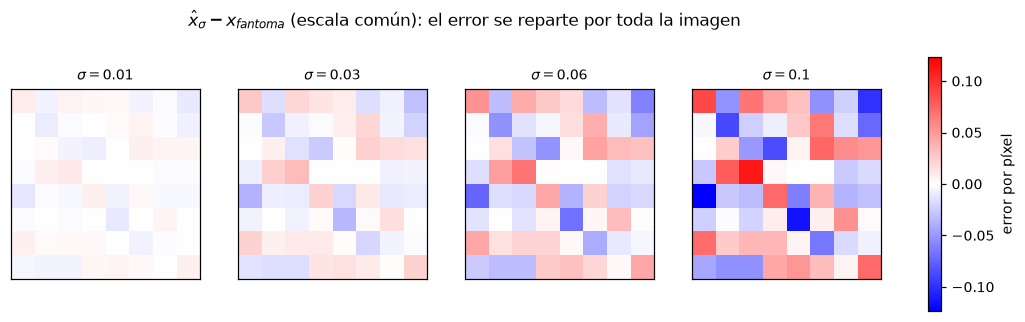

In [8]:
# Diferencias respecto del fantoma, con escala simétrica común a los cuatro paneles.
lim = max(np.abs(reconstrucciones[s] - x_fantoma).max() for s in sigmas)

fig, axes = plt.subplots(1, 4, figsize=(11.0, 3.0))
for ax, s in zip(axes, sigmas[1:]):
    im = ax.imshow((reconstrucciones[s] - x_fantoma).reshape(n, n),
                   cmap="bwr", vmin=-lim, vmax=lim)
    ax.set_title(fr"$\sigma = {s}$", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes, fraction=0.022, label="error por píxel")
fig.suptitle(r"$\hat{x}_\sigma - x_{fantoma}$ (escala común): el error se reparte "
             r"por toda la imagen", y=1.02)
guardar(fig, "ejercicio_06b_errores")
plt.show()

## c) Análisis

### ¿Cómo cambia el error de reconstrucción al aumentar $\sigma$?

Crece **linealmente**, y el gráfico de la izquierda lo muestra con una recta casi perfecta.
La razón es que todo el proceso es lineal: si $A_7$ tiene rango columna completo, la
solución de mínimos cuadrados es $\hat{x}_\sigma = A_7^{+}b_\sigma$ con
$A_7^{+} = (A_7^{T}A_7)^{-1}A_7^{T}$, y por linealidad

$$\hat{x}_\sigma - x_{\text{fantoma}} = A_7^{+}(b_7 + \eta_\sigma) - A_7^{+}b_7
= A_7^{+}\eta_\sigma = \sigma\,\text{escala}\;A_7^{+}z .$$

El error es exactamente proporcional a $\sigma$. Su tamaño está gobernado por la cota
clásica

$$\frac{\|\hat{x}_\sigma - x\|}{\|x\|} \le \kappa(A_7)\,\frac{\|\eta_\sigma\|}{\|b_7\|},
\qquad \kappa(A_7) = \frac{\sigma_{\max}}{\sigma_{\min}} \approx 8.4 .$$

En nuestro caso la amplificación observada es $\approx 2$, bastante por debajo de la cota,
porque el ruido gaussiano se reparte entre todas las direcciones singulares y no se
concentra en la peor. Aun así, un ruido del $10\%$ en las mediciones produce un error del
$16\%$ en la imagen: el problema inverso **amplifica** el ruido.

### ¿Por qué el residuo deja de ser nulo?

Porque el vector de mediciones deja de pertenecer al espacio columna. Formalmente,
$\operatorname{Col}(A_7)$ es un subespacio de dimensión $64$ dentro de $\mathbb{R}^{119}$;
$b_7$ vive en él por construcción, pero $\eta_\sigma$ es un vector aleatorio de
$\mathbb{R}^{119}$ que tiene componente en $\operatorname{Col}(A_7)^{\perp}$, un subespacio
de dimensión $55$. Descomponiendo

$$\eta_\sigma = \underbrace{\eta_{\parallel}}_{\in\,\operatorname{Col}(A_7)}
+ \underbrace{\eta_{\perp}}_{\in\,\operatorname{Col}(A_7)^{\perp}},$$

mínimos cuadrados puede ajustar exactamente $b_7 + \eta_{\parallel}$ (esa parte se cuela en
la reconstrucción como error), pero $\eta_{\perp}$ es **imposible** de reproducir con
ninguna imagen. El residuo mínimo es precisamente $r = \eta_{\perp}$, y por eso
$\|r\|/\|\eta\|$ se mantiene constante. Lo verificamos numéricamente abajo.

Dicho de otro modo: el residuo no nulo es una **buena** señal. Indica que el modelo no está
ajustando el ruido; si lográramos residuo cero con datos ruidosos, sería porque el modelo
tiene suficientes grados de libertad como para reproducir el ruido, lo cual sería
sobreajuste.

### ¿Por qué aparecen valores negativos si $\mu \ge 0$?

Porque el modelo lineal **no incorpora** la restricción de no negatividad. El problema
resuelto es

$$\min_{x \in \mathbb{R}^{64}} \|A_7 x - b_\sigma\|^2$$

sobre **todo** $\mathbb{R}^{64}$, no sobre el cono $\{x \ge 0\}$. La solución es una
transformación lineal de los datos, $\hat{x}_\sigma = A_7^{+}b_\sigma$, y una transformación
lineal aplicada a un dato ruidoso puede devolver componentes negativas. Concretamente, en
las zonas donde el fantoma vale exactamente $0$ (todo el borde), el valor verdadero está
*en la frontera* del rango físico: cualquier perturbación tiene un $50\%$ de probabilidad de
empujarlo hacia abajo. En la tabla se ve que el mínimo pasa de $0.000$ a $-0.123$ a medida
que $\sigma$ crece.

Estos valores negativos no tienen sentido físico y son un síntoma de que la reconstrucción
está siguiendo el ruido. Hay dos maneras de atacarlo: imponer explícitamente $x \ge 0$
(mínimos cuadrados no negativos), o **regularizar** — agregar un término que penalice
soluciones poco plausibles, que es el camino que sigue el trabajo en el Ejercicio 9.

In [9]:
# Verificación: el residuo es exactamente la componente del ruido ortogonal a Col(A7).
Q, _ = np.linalg.qr(A7)                 # base ortonormal de Col(A7)

print(f"{'σ':>6} {'||r||':>10} {'||η_perp||':>12} {'||η_par||':>11} {'¿r = η_perp?':>14}")
print("-" * 57)
for s in sigmas:
    eta = b_sigma[s] - b7
    eta_par = Q @ (Q.T @ eta)
    eta_perp = eta - eta_par
    r = b_sigma[s] - A7 @ reconstrucciones[s]
    print(f"{s:>6} {np.linalg.norm(r):>10.5f} {np.linalg.norm(eta_perp):>12.5f} "
          f"{np.linalg.norm(eta_par):>11.5f} "
          f"{str(np.allclose(r, eta_perp, atol=1e-8)):>14}")
print()
print("dim Col(A7) =", np.linalg.matrix_rank(A7),
      "   dim Col(A7)^perp =", A7.shape[0] - np.linalg.matrix_rank(A7))

     σ      ||r||   ||η_perp||   ||η_par||   ¿r = η_perp?
---------------------------------------------------------
   0.0    0.00000      0.00000     0.00000           True
  0.01    0.05851      0.05851     0.07371           True
  0.03    0.17554      0.17554     0.22113           True
  0.06    0.35109      0.35109     0.44226           True
   0.1    0.58515      0.58515     0.73709           True

dim Col(A7) = 64    dim Col(A7)^perp = 55


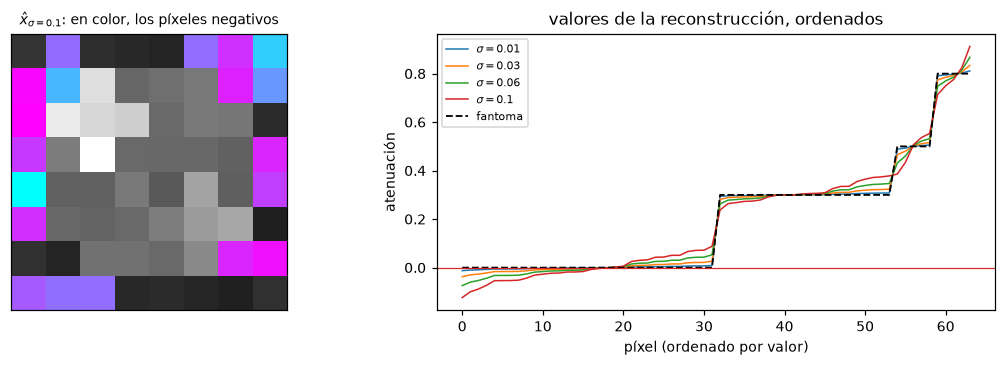

In [10]:
# Los valores negativos se concentran donde el fantoma vale 0.
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.4))

s = 0.10
X_hat = reconstrucciones[s].reshape(n, n)
negativos = np.ma.masked_where(X_hat >= 0, X_hat)
axes[0].imshow(X_hat, cmap="gray", vmin=vmin, vmax=vmax)
axes[0].imshow(negativos, cmap="cool", vmin=X_hat.min(), vmax=0)
axes[0].set_title(fr"$\hat{{x}}_{{\sigma={s}}}$: en color, los píxeles negativos", fontsize=9)
axes[0].set_xticks([]); axes[0].set_yticks([])

for sg in sigmas[1:]:
    xh = reconstrucciones[sg]
    axes[1].plot(np.sort(xh), lw=1.0, label=fr"$\sigma={sg}$")
axes[1].plot(np.sort(x_fantoma), "k--", lw=1.2, label="fantoma")
axes[1].axhline(0, color="tab:red", lw=0.8)
axes[1].set_title("valores de la reconstrucción, ordenados")
axes[1].set_xlabel("píxel (ordenado por valor)")
axes[1].set_ylabel("atenuación")
axes[1].legend(fontsize=7)

fig.tight_layout()
guardar(fig, "ejercicio_06c_negativos")
plt.show()

### Síntesis del ejercicio

Con $A_7$ de rango columna completo el problema tiene **solución única** para todo nivel de
ruido, y el residuo pasa a ser no nulo porque las mediciones ruidosas salen del espacio
columna. Mínimos cuadrados hace lo mejor posible: proyecta $b_\sigma$ ortogonalmente sobre
$\operatorname{Col}(A_7)$ — esa interpretación geométrica es exactamente lo que formaliza el
Ejercicio 7. Pero unicidad no es lo mismo que calidad: el error crece proporcionalmente al
ruido y aparecen artefactos sin sentido físico. Eso motiva agregar información *a priori*
sobre la imagen mediante regularización.